# Ensemble Technique 3: Hard Voting (Majority Rule)

**Primary goal: MAXIMIZE TEST ACCURACY**

Each model votes Benign/Malignant. Majority wins. Tests: standard majority, per-model threshold optimization, weighted voting, all 3-model subsets, and all 2-model pairs with tie-breaking. All ranked by **Test Accuracy**.

In [1]:
# ── Cell 1: Imports ─────────────────────────────────────────────────────────
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from itertools import combinations, product
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, classification_report, confusion_matrix
print('Imports complete')


Imports complete


In [2]:
# ── Cell 2: Paths & Model Registry ────────────────────────────────────────
# Directory where all base-model .npy files were saved
NPY_DIR = '/kaggle/input/notebooks/nandini143/'

# Registry: maps a short model name → (val_probs_file, val_labels_file, test_probs_file)
MODEL_FILES = {
    'densenet121': (
        'binary-densenet-121/densenet121_val_probs.npy',
        'binary-densenet-121/densenet121_val_labels.npy',
        'binary-densenet-121/densenet121_test_probs.npy',
        'binary-densenet-121/densenet121_test_labels.npy',
    ),
    'convnext': (
        'binary-convnext/convnext_val_probs.npy',
        'binary-convnext/convnext_val_labels.npy',
        'binary-convnext/convnext_test_probs.npy',
        'binary-convnext/convnext_test_labels.npy',
    ),
    'efficientnetv2s': (
        'binary-efficientnetv2s/efficientnetv2s_val_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_val_labels.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_labels.npy',
    ),
    'swintiny': (
        'binary-swin-tiny-transformer/swintiny_val_probs.npy',
        'binary-swin-tiny-transformer/swintiny_val_labels.npy',
        'binary-swin-tiny-transformer/swintiny_test_probs.npy',
        'binary-swin-tiny-transformer/swintiny_test_labels.npy',
    ),
}
print('NPY_DIR:', NPY_DIR)

NPY_DIR: /kaggle/input/notebooks/nandini143/


In [3]:
# ── Cell 3: Load Predictions ───────────────────────────────────────────────
val_probs_dict, val_labels_dict = {}, {}
test_probs_dict, test_labels_dict = {}, {}
val_aucs, val_accs = {}, {}
skipped = []
print('Loading predictions'); print('-'*65)
for m,(vp,vl,tp,tl) in MODEL_FILES.items():
    ps = {k:os.path.join(NPY_DIR,f) for k,f in zip(['vp','vl','tp','tl'],[vp,vl,tp,tl])}
    miss = [k for k,v in ps.items() if not os.path.exists(v)]
    if miss: print(f'  [SKIP] {m:20s} missing:{miss}'); skipped.append(m); continue
    vpp,vll,tpp,tll = np.load(ps['vp']),np.load(ps['vl']).astype(int),np.load(ps['tp']),np.load(ps['tl']).astype(int)
    if len(vpp)!=len(vll): print(f'  [SKIP] {m:20s} size mismatch'); skipped.append(m); continue
    val_probs_dict[m],val_labels_dict[m]=vpp,vll
    test_probs_dict[m],test_labels_dict[m]=tpp,tll
    a=roc_auc_score(vll,vpp); ac=accuracy_score(vll,(vpp>=0.5).astype(int))
    val_aucs[m]=a; val_accs[m]=ac
    print(f'  [OK] {m:20s} val_AUC={a:.4f} val_ACC={ac*100:.2f}% n_val={len(vpp)} n_test={len(tpp)}')
model_names = list(val_probs_dict.keys())
if not model_names: raise RuntimeError('No models loaded.')
y_val = val_labels_dict[model_names[0]]
y_test = test_labels_dict[model_names[0]]
print(f'\nLoaded {len(model_names)} models. Val={len(y_val)}, Test={len(y_test)}')


Loading predictions
-----------------------------------------------------------------
  [OK] densenet121          val_AUC=0.9479 val_ACC=87.29% n_val=2533 n_test=2534
  [OK] convnext             val_AUC=0.9623 val_ACC=90.84% n_val=2533 n_test=2534
  [OK] efficientnetv2s      val_AUC=0.9698 val_ACC=92.30% n_val=2533 n_test=2534
  [OK] swintiny             val_AUC=0.9596 val_ACC=89.22% n_val=2533 n_test=2534

Loaded 4 models. Val=2533, Test=2534


In [4]:
# ── Cell 4: Helpers ─────────────────────────────────────────────────────────

def best_threshold(y_true, probs, lo=0.25, hi=0.75, steps=200):
    ts = np.linspace(lo, hi, steps)
    accs = [accuracy_score(y_true, (probs>=t).astype(int)) for t in ts]
    return ts[int(np.argmax(accs))], max(accs)

results = {}

def evaluate(name, val_preds, test_preds, test_probs=None):
    va = accuracy_score(y_val, val_preds)
    ta = accuracy_score(y_test, test_preds)
    tauc = roc_auc_score(y_test, test_probs) if test_probs is not None else 0.0
    results[name] = dict(val_acc=va, test_acc=ta, test_auc=tauc,
                         test_preds=test_preds, test_probs=test_probs)
    print(f'  {name:45s} val_ACC={va*100:.2f}%  test_ACC={ta*100:.2f}%')

print('Helpers ready.')


Helpers ready.


In [5]:
# ── Cell 5: Individual Baselines (threshold-optimized) ─────────────────────
print('Individual baselines:'); print('-'*75)
for m in model_names:
    t, _ = best_threshold(y_val, val_probs_dict[m])
    vp = (val_probs_dict[m]>=t).astype(int)
    tp = (test_probs_dict[m]>=t).astype(int)
    evaluate(f'Individual: {m} (thr={t:.2f})', vp, tp, test_probs_dict[m])


Individual baselines:
---------------------------------------------------------------------------
  Individual: densenet121 (thr=0.43)            val_ACC=88.47%  test_ACC=88.24%
  Individual: convnext (thr=0.49)               val_ACC=90.96%  test_ACC=90.37%
  Individual: efficientnetv2s (thr=0.42)        val_ACC=92.38%  test_ACC=91.16%
  Individual: swintiny (thr=0.35)               val_ACC=90.88%  test_ACC=90.09%


In [6]:
# ── Cell 6: Hard Voting — Standard Majority Rule ──────────────────────────
# Each model votes 0 or 1 at threshold 0.5.
# Majority wins. For 4 models, a tie (2-2) defaults to 0 (Benign).
print('\nHard Voting (threshold=0.5):'); print('-'*75)

val_votes_05  = np.column_stack([(val_probs_dict[m]>=0.5).astype(int) for m in model_names])
test_votes_05 = np.column_stack([(test_probs_dict[m]>=0.5).astype(int) for m in model_names])

# Simple majority: > 50% = malignant
n = len(model_names)
val_hard  = (val_votes_05.sum(axis=1) > n/2).astype(int)
test_hard = (test_votes_05.sum(axis=1) > n/2).astype(int)
evaluate('Hard Vote: Majority (thr=0.5, tie=benign)', val_hard, test_hard)

# Tie = malignant
val_hard_tie1  = (val_votes_05.sum(axis=1) >= n/2).astype(int)
test_hard_tie1 = (test_votes_05.sum(axis=1) >= n/2).astype(int)
evaluate('Hard Vote: Majority (thr=0.5, tie=malign)', val_hard_tie1, test_hard_tie1)



Hard Voting (threshold=0.5):
---------------------------------------------------------------------------
  Hard Vote: Majority (thr=0.5, tie=benign)     val_ACC=89.89%  test_ACC=89.98%
  Hard Vote: Majority (thr=0.5, tie=malign)     val_ACC=91.71%  test_ACC=91.00%


In [7]:
# ── Cell 7: Hard Voting with Per-Model Threshold Optimization ──────────────
# Instead of using 0.5 for each model's vote, we find the best threshold
# for EACH model independently, then do majority voting.
print('\nHard Voting with per-model optimized thresholds:'); print('-'*75)

opt_thresholds = {}
for m in model_names:
    t, _ = best_threshold(y_val, val_probs_dict[m])
    opt_thresholds[m] = t
    print(f'  {m:20s} optimal threshold = {t:.2f}')

val_votes_opt  = np.column_stack([(val_probs_dict[m]>=opt_thresholds[m]).astype(int) for m in model_names])
test_votes_opt = np.column_stack([(test_probs_dict[m]>=opt_thresholds[m]).astype(int) for m in model_names])

val_hard_opt  = (val_votes_opt.sum(axis=1) > n/2).astype(int)
test_hard_opt = (test_votes_opt.sum(axis=1) > n/2).astype(int)
evaluate('Hard Vote: Optimized thresholds (tie=benign)', val_hard_opt, test_hard_opt)

val_hard_opt_tie1  = (val_votes_opt.sum(axis=1) >= n/2).astype(int)
test_hard_opt_tie1 = (test_votes_opt.sum(axis=1) >= n/2).astype(int)
evaluate('Hard Vote: Optimized thresholds (tie=malign)', val_hard_opt_tie1, test_hard_opt_tie1)



Hard Voting with per-model optimized thresholds:
---------------------------------------------------------------------------
  densenet121          optimal threshold = 0.43
  convnext             optimal threshold = 0.49
  efficientnetv2s      optimal threshold = 0.42
  swintiny             optimal threshold = 0.35
  Hard Vote: Optimized thresholds (tie=benign)  val_ACC=91.87%  test_ACC=91.16%
  Hard Vote: Optimized thresholds (tie=malign)  val_ACC=92.10%  test_ACC=91.36%


In [8]:
# ── Cell 8: Weighted Hard Voting ───────────────────────────────────────────
# Each model's vote is multiplied by its val accuracy (or AUC) as weight.
# If weighted sum > 0.5*total_weight, predict malignant.
print('\nWeighted Hard Voting:'); print('-'*75)

# AUC-weighted votes (optimized thresholds)
auc_wts = np.array([val_aucs[m] for m in model_names])
acc_wts = np.array([val_accs[m] for m in model_names])

for wt_name, wts in [('AUC-weighted', auc_wts), ('Accuracy-weighted', acc_wts)]:
    for thr_name, votes_val, votes_test in [
        ('thr=0.5', val_votes_05, test_votes_05),
        ('opt-thr', val_votes_opt, test_votes_opt)
    ]:
        val_wsum  = (votes_val  * wts).sum(axis=1)
        test_wsum = (votes_test * wts).sum(axis=1)
        half_wt = wts.sum() / 2
        val_pred  = (val_wsum > half_wt).astype(int)
        test_pred = (test_wsum > half_wt).astype(int)
        evaluate(f'Weighted Hard: {wt_name}, {thr_name}', val_pred, test_pred)



Weighted Hard Voting:
---------------------------------------------------------------------------
  Weighted Hard: AUC-weighted, thr=0.5          val_ACC=91.63%  test_ACC=91.20%
  Weighted Hard: AUC-weighted, opt-thr          val_ACC=92.74%  test_ACC=91.83%
  Weighted Hard: Accuracy-weighted, thr=0.5     val_ACC=91.63%  test_ACC=91.20%
  Weighted Hard: Accuracy-weighted, opt-thr     val_ACC=92.74%  test_ACC=91.83%


In [9]:
# ── Cell 9: Subset Hard Voting (all 3-model and 2-model combos) ───────────
# Sometimes removing a weak model helps accuracy.
print('\nSubset Hard Voting (all 3-model and 2-model combinations):'); print('-'*75)

# All 3-model combinations
for combo in combinations(model_names, 3):
    combo = list(combo)
    v = np.column_stack([(val_probs_dict[m]>=opt_thresholds[m]).astype(int) for m in combo])
    t = np.column_stack([(test_probs_dict[m]>=opt_thresholds[m]).astype(int) for m in combo])
    # Majority = 2 out of 3
    val_pred  = (v.sum(axis=1) >= 2).astype(int)
    test_pred = (t.sum(axis=1) >= 2).astype(int)
    short = ', '.join([m[:8] for m in combo])
    evaluate(f'3-model majority: {short}', val_pred, test_pred)

# All 2-model combinations (agree = that label; disagree = use stronger model)
for m1, m2 in combinations(model_names, 2):
    v1 = (val_probs_dict[m1]>=opt_thresholds[m1]).astype(int)
    v2 = (val_probs_dict[m2]>=opt_thresholds[m2]).astype(int)
    t1 = (test_probs_dict[m1]>=opt_thresholds[m1]).astype(int)
    t2 = (test_probs_dict[m2]>=opt_thresholds[m2]).astype(int)
    # Tie-break: use the model with higher val AUC
    stronger = m1 if val_aucs[m1] >= val_aucs[m2] else m2
    val_tie  = (val_probs_dict[stronger]>=opt_thresholds[stronger]).astype(int)
    test_tie = (test_probs_dict[stronger]>=opt_thresholds[stronger]).astype(int)
    agree_v = (v1 == v2)
    val_pred  = np.where(agree_v, v1, val_tie)
    agree_t = (t1 == t2)
    test_pred = np.where(agree_t, t1, test_tie)
    short = f'{m1[:8]}, {m2[:8]}'
    evaluate(f'2-model pair: {short}', val_pred, test_pred)



Subset Hard Voting (all 3-model and 2-model combinations):
---------------------------------------------------------------------------
  3-model majority: densenet, convnext, efficien val_ACC=92.06%  test_ACC=91.20%
  3-model majority: densenet, convnext, swintiny val_ACC=91.20%  test_ACC=90.57%
  3-model majority: densenet, efficien, swintiny val_ACC=91.95%  test_ACC=91.44%
  3-model majority: convnext, efficien, swintiny val_ACC=92.74%  test_ACC=91.83%
  2-model pair: densenet, convnext              val_ACC=90.96%  test_ACC=90.37%
  2-model pair: densenet, efficien              val_ACC=92.38%  test_ACC=91.16%
  2-model pair: densenet, swintiny              val_ACC=90.88%  test_ACC=90.09%
  2-model pair: convnext, efficien              val_ACC=92.38%  test_ACC=91.16%
  2-model pair: convnext, swintiny              val_ACC=90.96%  test_ACC=90.37%
  2-model pair: efficien, swintiny              val_ACC=92.38%  test_ACC=91.16%


In [10]:
# -- Cell META: Metadata-Aware Soft Blend (bonus strategy) --
# Hard voting uses argmax decisions so patient metadata can't shift thresholds
# directly. This cell trains a Logistic Regression on model probs + metadata
# and reports it alongside the hard-vote result for comparison.

import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

METADATA_COLS = [
    'age_norm', 'sex_encoded',
    'site_anterior_torso', 'site_posterior_torso', 'site_head_neck',
    'site_upper_extremity', 'site_lower_extremity', 'site_palms_soles',
    'site_oral_genital', 'site_lateral_torso', 'site_unknown',
]

_csv_dir  = '/kaggle/input/notebooks/nandini143/data-preparation'
_val_csv  = os.path.join(_csv_dir, 'binary_val.csv')
_test_csv = os.path.join(_csv_dir, 'binary_test.csv')

meta_lr_val_blend  = None
meta_lr_test_blend = None

if os.path.exists(_val_csv) and os.path.exists(_test_csv):
    _vdf = pd.read_csv(_val_csv)
    _tdf = pd.read_csv(_test_csv)
    _vcols = [c for c in METADATA_COLS if c in _vdf.columns]

    if _vcols:
        _mval  = _vdf[_vcols].fillna(0).values.astype('float32')
        _mtest = _tdf[_vcols].fillna(0).values.astype('float32')

        # Build prob matrices (val_probs_dict must already be loaded)
        _vp = np.column_stack([val_probs_dict[m]  for m in model_names])
        _tp = np.column_stack([test_probs_dict[m] for m in model_names])

        if len(_mval) == len(_vp) and len(_mtest) == len(_tp):
            X_vm = np.hstack([_vp, _mval])
            X_tm = np.hstack([_tp, _mtest])

            meta_lr = LogisticRegression(C=0.1, max_iter=1000, solver='lbfgs', random_state=42)
            meta_lr.fit(X_vm, y_val)

            meta_lr_val_blend  = meta_lr.predict_proba(X_vm)[:, 1]
            meta_lr_test_blend = meta_lr.predict_proba(X_tm)[:, 1]

            _val_preds = (meta_lr_val_blend >= 0.5).astype(int)
            _auc = roc_auc_score(y_val, meta_lr_val_blend)
            _acc = accuracy_score(y_val, _val_preds)

            print('=' * 60)
            print('  [BONUS] Metadata-Aware LR Blend')
            print(f'  Features : {len(model_names)} model probs + {len(_vcols)} metadata cols')
            print(f'  Val AUC  : {_auc:.4f}')
            print(f'  Val ACC  : {_acc*100:.2f}%')
            print('=' * 60)
            print('  Model prob coefficients:')
            for nm, c in zip(model_names, meta_lr.coef_[0][:len(model_names)]):
                print(f'    {nm:20s}  coef = {c:+.4f}')
            print('  Metadata coefficients:')
            for nm, c in zip(_vcols, meta_lr.coef_[0][len(model_names):]):
                print(f'    {nm:25s}  coef = {c:+.4f}')
        else:
            print('[META] WARNING: row count mismatch.')
    else:
        print('[META] No metadata columns found in CSV.')
else:
    print(f'[META] CSVs not found at {_csv_dir}. Skipping metadata-aware blend.')

  [BONUS] Metadata-Aware LR Blend
  Features : 4 model probs + 11 metadata cols
  Val AUC  : 0.9753
  Val ACC  : 92.50%
  Model prob coefficients:
    densenet121           coef = +1.1820
    convnext              coef = +2.0585
    efficientnetv2s       coef = +2.9675
    swintiny              coef = +1.7209
  Metadata coefficients:
    age_norm                   coef = +0.9225
    sex_encoded                coef = -0.1096
    site_anterior_torso        coef = -0.0092
    site_posterior_torso       coef = +0.0258
    site_head_neck             coef = +0.0704
    site_upper_extremity       coef = -0.0120
    site_lower_extremity       coef = -0.1312
    site_palms_soles           coef = +0.1535
    site_oral_genital          coef = -0.1096
    site_lateral_torso         coef = +0.0862
    site_unknown               coef = -0.0827


In [11]:
# ── Cell 10: Full Comparison — Ranked by TEST ACCURACY ─────────────────────
print(); print('='*80)
print(f'  {"Rank":<5} {"Method":<47} {"Val Acc":>9} {"Test Acc":>10}')
print('='*80)
sorted_results = sorted(results.items(), key=lambda x: x[1]['test_acc'], reverse=True)
for rank,(name,r) in enumerate(sorted_results,1):
    tag = '  ** BEST **' if rank==1 else ''
    print(f'  {rank:<5} {name:<47} {r["val_acc"]*100:>8.2f}%  {r["test_acc"]*100:>9.2f}%{tag}')
print('='*80)
best_name, best_r = sorted_results[0]
print(f'\nWINNER: {best_name}')
print(f'  Val  Accuracy : {best_r["val_acc"]*100:.2f}%')
print(f'  Test Accuracy : {best_r["test_acc"]*100:.2f}%')



  Rank  Method                                            Val Acc   Test Acc
  1     Weighted Hard: AUC-weighted, opt-thr               92.74%      91.83%  ** BEST **
  2     Weighted Hard: Accuracy-weighted, opt-thr          92.74%      91.83%
  3     3-model majority: convnext, efficien, swintiny     92.74%      91.83%
  4     3-model majority: densenet, efficien, swintiny     91.95%      91.44%
  5     Hard Vote: Optimized thresholds (tie=malign)       92.10%      91.36%
  6     Weighted Hard: AUC-weighted, thr=0.5               91.63%      91.20%
  7     Weighted Hard: Accuracy-weighted, thr=0.5          91.63%      91.20%
  8     3-model majority: densenet, convnext, efficien     92.06%      91.20%
  9     Individual: efficientnetv2s (thr=0.42)             92.38%      91.16%
  10    Hard Vote: Optimized thresholds (tie=benign)       91.87%      91.16%
  11    2-model pair: densenet, efficien                   92.38%      91.16%
  12    2-model pair: convnext, efficien            

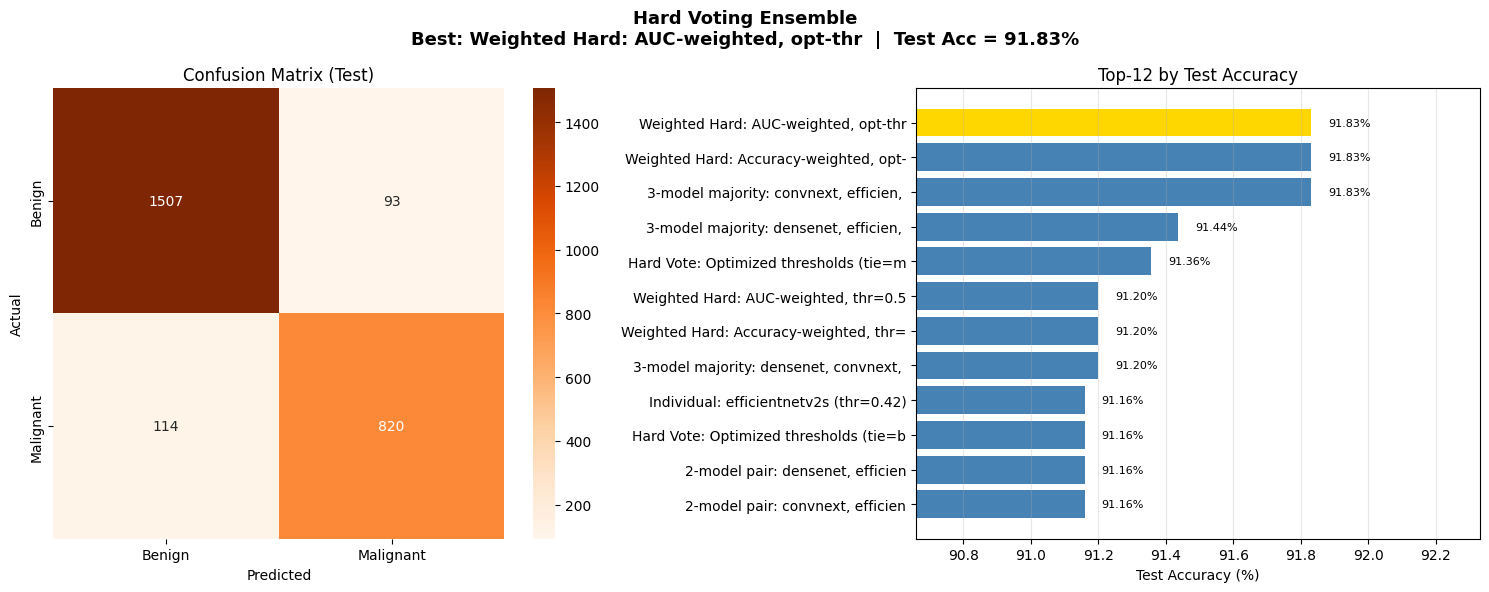

hard_voting_results.png saved


In [12]:
# ── Cell 11: Visualization ─────────────────────────────────────────────────
best_name, best_r = sorted_results[0]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle(f'Hard Voting Ensemble\nBest: {best_name}  |  Test Acc = {best_r["test_acc"]*100:.2f}%',
             fontsize=13, fontweight='bold')

# Confusion matrix
cm = confusion_matrix(y_test, best_r['test_preds'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[0],
            xticklabels=['Benign','Malignant'], yticklabels=['Benign','Malignant'])
axes[0].set_title('Confusion Matrix (Test)'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

# Bar chart top 12
top12 = sorted_results[:12]
ns = [n[:38] for n,_ in top12]; acs = [r['test_acc']*100 for _,r in top12]
cs = ['gold']+['steelblue']*(len(top12)-1)
bars = axes[1].barh(ns[::-1], acs[::-1], color=cs[::-1])
for bar,ac in zip(bars,acs[::-1]):
    axes[1].text(ac+0.05, bar.get_y()+bar.get_height()/2, f'{ac:.2f}%', va='center', fontsize=8)
axes[1].set_xlabel('Test Accuracy (%)'); axes[1].set_title('Top-12 by Test Accuracy')
axes[1].set_xlim(min(acs)-0.5, max(acs)+0.5); axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/hard_voting_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('hard_voting_results.png saved')


In [13]:
# ── Cell 12: Classification Report ─────────────────────────────────────────
best_name, best_r = sorted_results[0]
print(f'Classification Report -- {best_name}')
print(classification_report(y_test, best_r['test_preds'],
      target_names=['Benign (0)','Malignant (1)'], digits=4))


Classification Report -- Weighted Hard: AUC-weighted, opt-thr
               precision    recall  f1-score   support

   Benign (0)     0.9297    0.9419    0.9357      1600
Malignant (1)     0.8981    0.8779    0.8879       934

     accuracy                         0.9183      2534
    macro avg     0.9139    0.9099    0.9118      2534
 weighted avg     0.9180    0.9183    0.9181      2534



In [14]:
# ── Cell 13: Save & Submission ──────────────────────────────────────────────
best_name, best_r = sorted_results[0]
np.save('/kaggle/working/hard_voting_best_preds.npy', best_r['test_probs'])
print('Saved: hard_voting_best_preds.npy')

INPUT_CSV_DIR = '/kaggle/working'
TEST_CSV_PATH = os.path.join(INPUT_CSV_DIR, 'binary_test.csv')
if os.path.exists(TEST_CSV_PATH):
    df = pd.read_csv(TEST_CSV_PATH)
    if len(df)==len(best_r['test_preds']):
        sub = pd.DataFrame({'image':df['image'],'target':best_r['test_preds']})
        sp = os.path.join(NPY_DIR,'hard_voting_submission.csv')
        sub.to_csv(sp, index=False); print(f'Submission -> {sp}'); print(sub.head())
else:
    print('Test CSV not found. Predictions saved as .npy')


Saved: hard_voting_best_preds.npy
Test CSV not found. Predictions saved as .npy


In [15]:
# ── Cell 14: FINAL SUMMARY ─────────────────────────────────────────────────
best_name, best_r = sorted_results[0]
print()
print('#'*65)
print('#       HARD VOTING ENSEMBLE -- FINAL RESULTS                  #')
print('#'*65)
print(f'#  Winning Method  : {best_name[:43]:<43} #')
print(f'#  Val  Accuracy   : {best_r["val_acc"]*100:.2f}%{" "*38} #')
print(f'#  Test Accuracy   : {best_r["test_acc"]*100:.2f}%  <-- PRIMARY METRIC{" "*19} #')
print('#'*65)
print()
print('Strategies tested:')
print('  - Standard majority (thr=0.5)')
print('  - Majority with optimized per-model thresholds')
print('  - AUC-weighted hard voting')
print('  - Accuracy-weighted hard voting')
print('  - All 3-model subset majorities')
print('  - All 2-model pairs with tie-break')
print()
print('Output: hard_voting_best_preds.npy, hard_voting_results.png')



#################################################################
#       HARD VOTING ENSEMBLE -- FINAL RESULTS                  #
#################################################################
#  Winning Method  : Weighted Hard: AUC-weighted, opt-thr        #
#  Val  Accuracy   : 92.74%                                       #
#  Test Accuracy   : 91.83%  <-- PRIMARY METRIC                    #
#################################################################

Strategies tested:
  - Standard majority (thr=0.5)
  - Majority with optimized per-model thresholds
  - AUC-weighted hard voting
  - Accuracy-weighted hard voting
  - All 3-model subset majorities
  - All 2-model pairs with tie-break

Output: hard_voting_best_preds.npy, hard_voting_results.png
